EJERCICIO 1


c) Periodo armonico T0 = 2*pi*sqrt(L/g) = 2.006067 s
theta0 (rad)  T numerico (s)  T teorico (s)      T/T0  Incremento  Ciclos
         0.1        2.007321       2.007321  1.000625      0.063%       7
         2.0        2.665871       2.665871  1.328904     32.890%       5


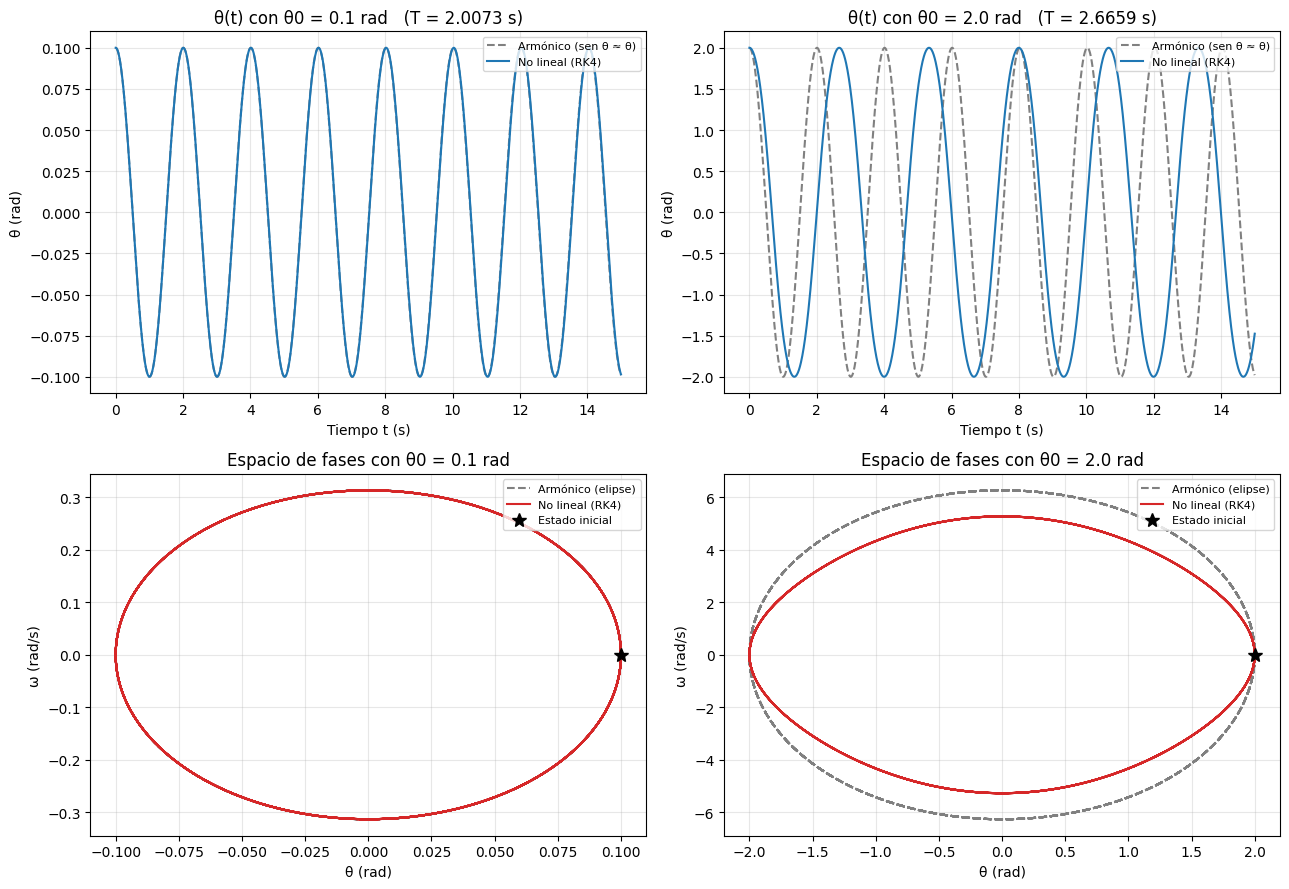

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# DATOS
g = 9.81            # m/s^2
L = 1.0             # m
w0_2 = g / L        # omega_0^2 (s^-2)
w0 = np.sqrt(w0_2)  # frecuencia angular armonica (rad/s)


# A) SISTEMA DE ECUACIONES
# u = [theta, omega]  ->  du/dt = [omega, -w0^2 * sen(theta)]
def F(u):
    theta, omega = u
    return np.array([omega, -w0_2 * np.sin(theta)])


# C) METODO RK4
def paso_rk4(u, h):
    k1 = F(u)
    k2 = F(u + (h / 2) * k1)
    k3 = F(u + (h / 2) * k2)
    k4 = F(u + h * k3)
    return u + (h / 6) * (k1 + 2 * k2 + 2 * k3 + k4)


# Repite el paso RK4 desde t = 0 hasta t = t_max partiendo del reposo
def simular(theta0, h, t_max):
    n_pasos = round(t_max / h)
    t = np.arange(n_pasos + 1) * h
    U = np.zeros((n_pasos + 1, 2))
    U[0] = [theta0, 0.0]
    for i in range(n_pasos):
        U[i + 1] = paso_rk4(U[i], h)
    return t, U


# Periodo medido en la simulacion: tiempo entre dos cruces consecutivos
# de theta por cero en el mismo sentido (de positivo a negativo)
def periodo_numerico(t, theta):
    cruces = []
    for i in range(len(t) - 1):
        if theta[i] > 0 and theta[i + 1] <= 0:
            # interpolacion lineal para ubicar el instante exacto del cruce
            fraccion = theta[i] / (theta[i] - theta[i + 1])
            cruces.append(t[i] + fraccion * (t[i + 1] - t[i]))
    return np.mean(np.diff(cruces)), len(cruces) - 1


# Periodo teorico exacto del pendulo no lineal: T = T0 / MAG(1, cos(theta0/2)),
# donde MAG es la media aritmetico-geometrica (equivale a la integral eliptica)
def periodo_teorico(theta0):
    a, b = 1.0, np.cos(theta0 / 2)
    for _ in range(30):
        a, b = (a + b) / 2, np.sqrt(a * b)
    return T0 / a


h = 0.01
t_max = 15.0
T0 = 2 * np.pi * np.sqrt(L / g)
amplitudes = [0.1, 2.0]

print(f"\nc) Periodo armonico T0 = 2*pi*sqrt(L/g) = {T0:.6f} s")
print(f"{'theta0 (rad)':>12} {'T numerico (s)':>15} {'T teorico (s)':>14} "
      f"{'T/T0':>9} {'Incremento':>11} {'Ciclos':>7}")

resultados = {}
for theta0 in amplitudes:
    t, U = simular(theta0, h, t_max)
    T_num, n_ciclos = periodo_numerico(t, U[:, 0])
    T_teo = periodo_teorico(theta0)
    resultados[theta0] = (t, U, T_num)
    incremento = (T_num / T0 - 1) * 100
    print(f"{theta0:>12.1f} {T_num:>15.6f} {T_teo:>14.6f} "
          f"{T_num / T0:>9.6f} {incremento:>10.3f}% {n_ciclos:>7d}")


# GRAFICAS
fig, ejes = plt.subplots(2, 2, figsize=(13, 9))

for columna, theta0 in enumerate(amplitudes):
    t, U, T_num = resultados[theta0]
    theta, omega = U[:, 0], U[:, 1]

    # Solucion armonica (pequeñas oscilaciones) con la misma amplitud
    theta_arm = theta0 * np.cos(w0 * t)
    omega_arm = -theta0 * w0 * np.sin(w0 * t)

    # Evolucion temporal theta(t)
    ax = ejes[0, columna]
    ax.plot(t, theta_arm, "--", color="gray", label="Armónico (sen θ ≈ θ)")
    ax.plot(t, theta, color="tab:blue", label="No lineal (RK4)")
    ax.set_xlabel("Tiempo t (s)")
    ax.set_ylabel("θ (rad)")
    ax.set_title(f"θ(t) con θ0 = {theta0} rad   (T = {T_num:.4f} s)")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.3)

    # Espacio de fases (theta, omega)
    ax = ejes[1, columna]
    ax.plot(theta_arm, omega_arm, "--", color="gray", label="Armónico (elipse)")
    ax.plot(theta, omega, color="tab:red", label="No lineal (RK4)")
    ax.plot(theta0, 0, "k*", markersize=10, label="Estado inicial")
    ax.set_xlabel("θ (rad)")
    ax.set_ylabel("ω (rad/s)")
    ax.set_title(f"Espacio de fases con θ0 = {theta0} rad")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("ejercicio1_pendulo.png", dpi=150)
plt.show()

EJERCICIO 2

b) Simulación RK4 del oscilador de Duffing (beta = 1,0)
   Pasos = 2000, h = 0.01 s, t_max = 20 s
   t (s)        x (m)      v (m/s)
    0.00     2.000000     0.000000
    2.00     0.560088     3.704991
    4.00    -1.265481     1.635506
    6.00    -0.349542    -2.422915
    8.00     0.980121    -0.100498
   10.00    -0.329042     1.581698
   12.00    -0.389412    -1.088516
   14.00     0.550042    -0.106595
   16.00    -0.246287     0.795074
   18.00    -0.122668    -0.694744
   20.00     0.287363     0.175516


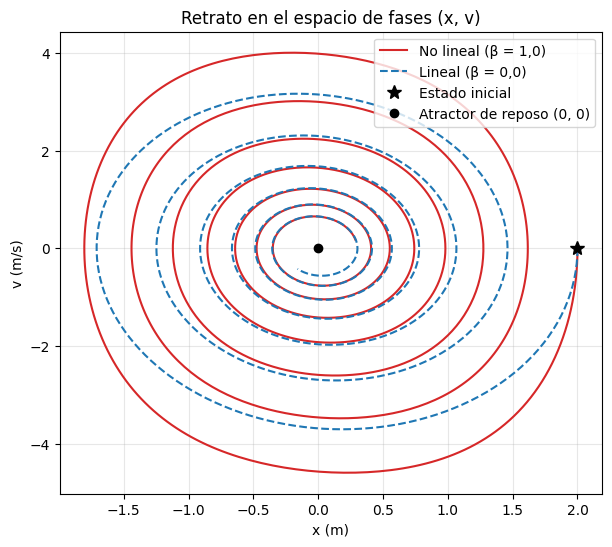

-----------------
No lineal (beta = 1,0)
Vuelta    t (s)  Amplitud (m)  Duración (s)
     1     2.48        1.6167          2.48
     2     5.15        1.2743          2.67
     3     7.97        0.9810          2.82
     4    10.92        0.7412          2.95
     5    13.95        0.5524          3.03
     6    17.03        0.4081          3.08
   Rapidez máxima = 4.5966 m/s
Lineal (beta = 0,0)
Vuelta    t (s)  Amplitud (m)  Duración (s)
     1     3.14        1.4601          3.14
     2     6.29        1.0661          3.15
     3     9.43        0.7783          3.14
     4    12.58        0.5683          3.15
     5    15.72        0.4149          3.14
     6    18.87        0.3029          3.15
   Rapidez máxima = 3.7068 m/s
-----------------
Rigidez efectiva k_ef = k + beta*x^2
   x = 2.0 m   k_ef = 8.00 N/m   (2.000 veces k)
   x = 1.0 m   k_ef = 5.00 N/m   (1.250 veces k)
   x = 0.5 m   k_ef = 4.25 N/m   (1.062 veces k)
   x = 0.1 m   k_ef = 4.01 N/m   (1.002 veces k)


In [9]:
import numpy as np
import matplotlib.pyplot as plt
m = 1
k = 4
gamma = 0.2
u0 = [2,0]
h = 0.01
t_max = 20

def F(u,beta):
  x,v = u
  return np.array([v,-gamma*v-(k/m)*x-(beta/m)*x**3])

def paso_rk4(u, h, beta):
  k1 = F(u,beta)
  k2 = F(u + (h/2)*k1,beta)
  k3 = F(u + (h/2)*k2,beta)
  k4 = F(u + h*k3,beta)
  return u + (h/6)*(k1+2*k2+2*k3+k4)

def simular(beta, u0, h, t_max):
  n_pasos = int(t_max / h)
  t = np.arange(n_pasos+1)*h
  U = np.zeros((n_pasos+1,2))
  U[0] = u0
  for i in range(n_pasos):
    U[i+1] = paso_rk4(U[i],h,beta)
  return t, U

t, U = simular(1.0, u0, h, t_max)
print("b) Simulación RK4 del oscilador de Duffing (beta = 1,0)")
print(f"   Pasos = {len(t) - 1}, h = {h} s, t_max = {t_max} s")
print(f"{'t (s)':>8} {'x (m)':>12} {'v (m/s)':>12}")
for i in range(0, len(t), 200):          # una fila cada 2 s
    print(f"{t[i]:>8.2f} {U[i, 0]:>12.6f} {U[i, 1]:>12.6f}")

#GRAFICOS Y DATOS CUANTITATIVOS
t_nl, U_nl = simular(1.0,u0,h,t_max)
t_lin, U_lin = simular(0.0,u0,h,t_max)

plt.figure(figsize=(7, 6))
plt.plot(U_nl[:,0], U_nl[:,1], "-",  color="tab:red",  label="No lineal (β = 1,0)")
plt.plot(U_lin[:,0], U_lin[:,1], "--", color="tab:blue", label="Lineal (β = 0,0)")
plt.plot(u0[0], u0[1], "k*", markersize=10, label="Estado inicial")
plt.plot(0, 0, "ko", label="Atractor de reposo (0, 0)")
plt.xlabel("x (m)")
plt.ylabel("v (m/s)")
plt.title("Retrato en el espacio de fases (x, v)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("ejercicio2_duffing.png", dpi=150)
plt.show()

def vueltas(t, U):
    x, v = U[:, 0], U[:, 1]
    tiempos, amplitudes = [0.0], [x[0]]
    for i in range(1, len(t) - 1):
        if v[i] > 0 and v[i + 1] <= 0:
            tiempos.append(t[i])
            amplitudes.append(x[i])
    return np.array(tiempos), np.array(amplitudes)
print("-----------------")
for nombre, U in (("No lineal (beta = 1,0)", U_nl), ("Lineal (beta = 0,0)", U_lin)):
    tm, am = vueltas(t_nl, U)
    print(nombre)
    print(f"{'Vuelta':>6} {'t (s)':>8} {'Amplitud (m)':>13} {'Duración (s)':>13}")
    for i in range(1, len(tm)):
        print(f"{i:>6d} {tm[i]:>8.2f} {am[i]:>13.4f} {tm[i] - tm[i - 1]:>13.2f}")
    print(f"   Rapidez máxima = {np.max(np.abs(U[:, 1])):.4f} m/s")
print("-----------------")
print("Rigidez efectiva k_ef = k + beta*x^2")
for x in (2.0, 1.0, 0.5, 0.1):
    k_ef = k + 1.0 * x**2
    print(f"   x = {x:.1f} m   k_ef = {k_ef:.2f} N/m   ({k_ef / k:.3f} veces k)")

EJERCICIO 3

b) Péndulo no lineal forzado y amortiguado
   Pasos = 6000, h = 0.01 s, t_max = 60 s
   t (s)      θ (rad)    w (rad/s)
    0.00     0.000000     0.000000
   10.00     0.030333    -0.020856
   20.00     0.031779    -0.030165
   30.00     0.019544    -0.035489
   40.00     0.001169    -0.037029
   50.00    -0.018542    -0.034113
   60.00    -0.035932    -0.026695


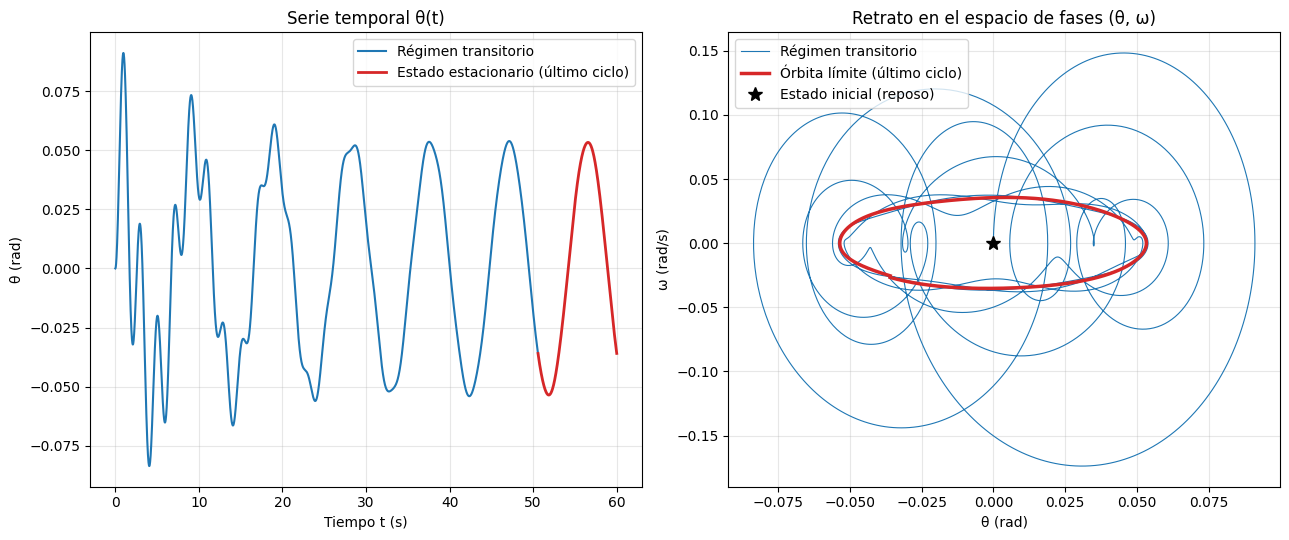

c) Último ciclo, de t = 50.58 s a t = 60.00 s
   Energía mecánica media        = 7.3045e-03 J/kg
   Energía disipada (rozamiento) = 1.1944e-03 J/kg
   Energía entregada (empujón)   = 1.2135e-03 J/kg
   Cambio neto de energía        = 1.901e-05 J/kg


In [20]:
import numpy as np
import matplotlib.pyplot as plt
w02 = 9.81
gamma = 0.2
f0 = 0.5
w_d=0.667
u0 = [0,0]
h = 0.01
t_max = 60

def F(t,u):
  teta,omega = u
  return np.array([omega,f0*np.cos(w_d*t)-w02*np.sin(teta)-gamma*omega])

def paso_rk4(t, u, h):
  k1 = F(t,u)
  k2 = F(t+(h/2),u + (h/2)*k1)
  k3 = F(t+(h/2),u + (h/2)*k2)
  k4 = F(t+h,u + h*k3)
  return u + (h/6)*(k1+2*k2+2*k3+k4)

def simular(u0, h, t_max):
  n_pasos = int(t_max / h)
  t = np.arange(n_pasos+1)*h
  U = np.zeros((n_pasos+1,2))
  U[0] = u0
  for i in range(n_pasos):
    U[i+1] = paso_rk4(t[i],U[i],h)
  return t, U

t, U = simular(u0, h, t_max)
print("b) Péndulo no lineal forzado y amortiguado")
print(f"   Pasos = {len(t) - 1}, h = {h} s, t_max = {t_max} s")
print(f"{'t (s)':>8} {'θ (rad)':>12} {'w (rad/s)':>12}")
for i in range(0, len(t), 1000):          # una fila cada 10 s
    print(f"{t[i]:>8.2f} {U[i, 0]:>12.6f} {U[i, 1]:>12.6f}")

#GRAFICOS Y DATOS CUANTITATIVOS
Td = 2 * np.pi / w_d          # período del empujón
n_ciclo = round(Td / h)       # pasos que dura un ciclo
i0 = len(t) - 1 - n_ciclo     # índice donde empieza el último ciclo

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

# Serie temporal θ(t)
ax1.plot(t[:i0 + 1], U[:i0 + 1, 0], color="tab:blue", label="Régimen transitorio")
ax1.plot(t[i0:], U[i0:,0], color="tab:red", lw=2, label="Estado estacionario (último ciclo)")
ax1.set_xlabel("Tiempo t (s)")
ax1.set_ylabel("θ (rad)")
ax1.set_title("Serie temporal θ(t)")
ax1.legend()
ax1.grid(alpha=0.3)

# Retrato en el espacio de fases (θ, ω)
ax2.plot( U[:i0 + 1, 0],  U[:i0 + 1, 1], color="tab:blue", lw=0.8, label="Régimen transitorio")
ax2.plot(U[i0:, 0], U[i0:, 1], color="tab:red", lw=2.5, label="Órbita límite (último ciclo)")
ax2.plot(0, 0, "k*", markersize=10, label="Estado inicial (reposo)")
ax2.set_xlabel("θ (rad)")
ax2.set_ylabel("ω (rad/s)")
ax2.set_title("Retrato en el espacio de fases (θ, ω)")
ax2.legend()
ax2.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("ejercicio3_forzado.png", dpi=150)
plt.show()

theta, omega = U[:, 0], U[:, 1]

E = 0.5 * omega**2 + w02 * (1 - np.cos(theta))   # energía mecánica (cinética + potencial)
P_roz = gamma * omega**2                         # energía por segundo que quita el rozamiento
P_emp = f0 * omega * np.cos(w_d * t)             # energía por segundo que entrega el empujón

# Suma por trapecios entre los índices i y j (área bajo la curva)
def integrar(f, i, j):
    return np.sum((f[i + 1:j + 1] + f[i:j]) / 2) * h

j = len(t) - 1                                   # último índice
print(f"c) Último ciclo, de t = {t[i0]:.2f} s a t = {t[j]:.2f} s")
print(f"   Energía mecánica media        = {np.mean(E[i0:]):.4e} J/kg")
print(f"   Energía disipada (rozamiento) = {integrar(P_roz, i0, j):.4e} J/kg")
print(f"   Energía entregada (empujón)   = {integrar(P_emp, i0, j):.4e} J/kg")
print(f"   Cambio neto de energía        = {E[j] - E[i0]:.3e} J/kg")

EJERCICIO 4

b) Tres cuerpos con RK4 (órbitas acopladas de Lagrange)
   Centro de masa     = (0.500000, 0.288675) UA
   Radio de la órbita = 0.577350 UA
   Velocidad angular  = 10.881980 rad/año
   Rapidez orbital    = 6.282714 UA/año
   Período orbital    = 0.577394 años
   Cuerpo 1: r = (0.000000, 0.000000) UA   v = (3.141357, -5.440990) UA/año
   Cuerpo 2: r = (1.000000, 0.000000) UA   v = (3.141357, 5.440990) UA/año
   Cuerpo 3: r = (0.500000, 0.866025) UA   v = (-6.282714, 0.000000) UA/año

   Pasos = 200, h = 0.01 años, T_sim = 2.0 años (3.46 vueltas)
 t (años)    x1 (UA)    y1 (UA)      E total
     0.00   0.000000   0.000000   -59.220587
     0.25   1.074317   0.347755   -59.220655
     0.50  -0.048299   0.469504   -59.220724
     0.75   0.926488  -0.100474   -59.220792
     1.00   0.269822   0.818153   -59.220860
     1.25   0.493652  -0.288636   -59.220929
     1.50   0.741754   0.812966   -59.220997
     1.75   0.065067  -0.091011   -59.221066
     2.00   1.052128   0.457431   -59.221134

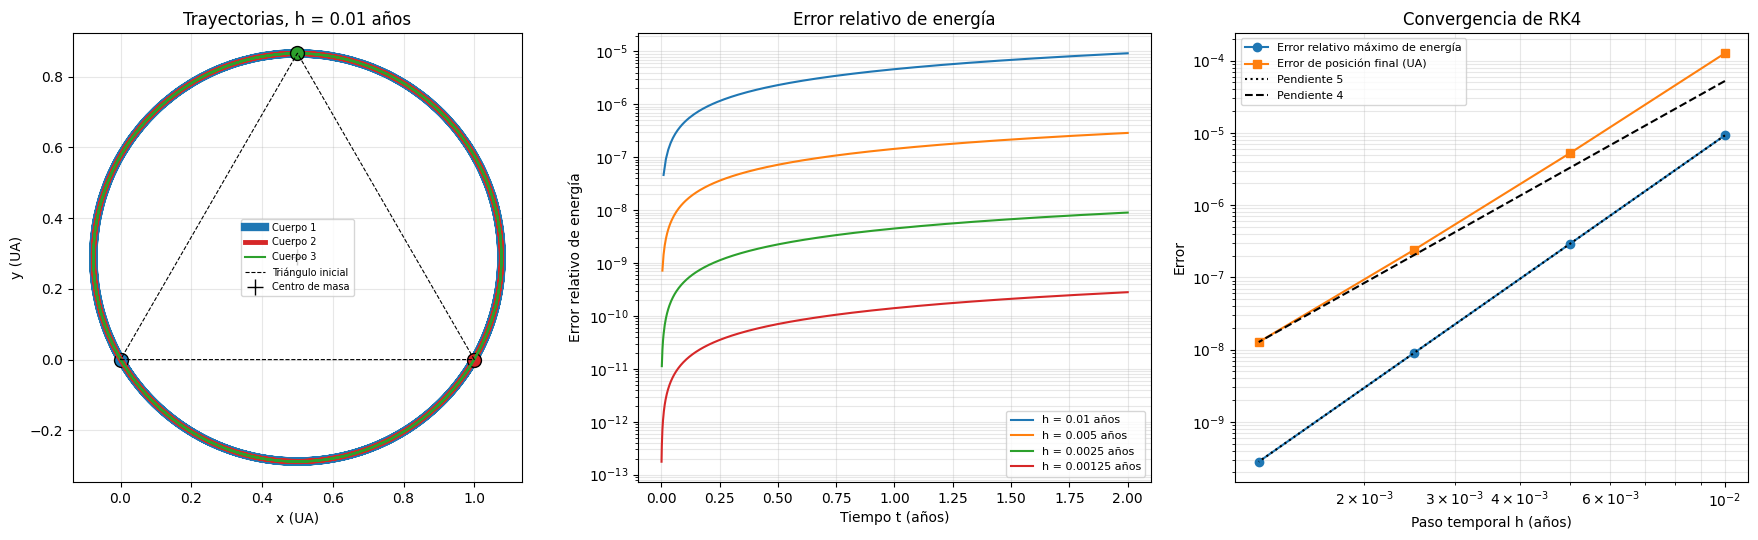

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# DATOS (unidades: UA, año y masa solar)
G = 4 * np.pi**2
m = [1.0, 1.0, 1.0]
R = 1.0          # lado del triángulo
eps = 0.01       # parámetro de suavizado
T_sim = 2.0      # tiempo total de simulación (años)

# u = [x1, y1, x2, y2, x3, y3, vx1, vy1, vx2, vy2, vx3, vy3]
def F(u):
    pos = u[:6].reshape(3, 2)      # fila i = posición (x, y) del cuerpo i
    vel = u[6:].reshape(3, 2)      # fila i = velocidad (vx, vy) del cuerpo i
    acel = np.zeros((3, 2))
    for i in range(3):
        for j in range(3):
            if j != i:
                d = pos[j] - pos[i]                       # vector del cuerpo i al cuerpo j
                dist2 = d[0]**2 + d[1]**2 + eps**2        # distancia al cuadrado, suavizada
                acel[i] += G * m[j] * d / dist2**1.5      # jalón del cuerpo j sobre el i
    return np.concatenate([vel.ravel(), acel.ravel()])


def paso_rk4(u, h):
    k1 = F(u)
    k2 = F(u + (h / 2) * k1)
    k3 = F(u + (h / 2) * k2)
    k4 = F(u + h * k3)
    return u + (h / 6) * (k1 + 2 * k2 + 2 * k3 + k4)


def simular(u0, h, T_sim):
    n_pasos = round(T_sim / h)
    t = np.arange(n_pasos + 1) * h
    U = np.zeros((n_pasos + 1, 12))
    U[0] = u0
    for i in range(n_pasos):
        U[i + 1] = paso_rk4(U[i], h)
    return t, U


# Energía mecánica total de un estado: cinética + potencial gravitacional
def energia(u):
    pos = u[:6].reshape(3, 2)
    vel = u[6:].reshape(3, 2)
    cinetica = 0.0
    for i in range(3):
        cinetica += 0.5 * m[i] * (vel[i, 0]**2 + vel[i, 1]**2)
    potencial = 0.0
    for i in range(3):
        for j in range(i + 1, 3):                         # cada par una sola vez
            d = pos[j] - pos[i]
            potencial -= G * m[i] * m[j] / np.sqrt(d[0]**2 + d[1]**2 + eps**2)
    return cinetica + potencial


pos0 = np.array([[0.0, 0.0],
                 [R, 0.0],
                 [R / 2, R * np.sqrt(3) / 2]])
centro = pos0.mean(axis=0)                           # centro de masa (masas iguales)
rel0 = pos0 - centro                                 # posiciones respecto al centro
radio = np.sqrt(rel0[0, 0]**2 + rel0[0, 1]**2)       # R / raíz(3)
Omega = np.sqrt(3 * G * m[0] / (R**2 + eps**2)**1.5)
vel0 = Omega * np.column_stack([-rel0[:, 1], rel0[:, 0]])   # velocidad perpendicular al radio
u0 = np.concatenate([pos0.ravel(), vel0.ravel()])
T_orbital = 2 * np.pi / Omega

h = 0.01
t, U = simular(u0, h, T_sim)
E = np.array([energia(u) for u in U])

print("b) Tres cuerpos con RK4 (órbitas acopladas de Lagrange)")
print(f"   Centro de masa     = ({centro[0]:.6f}, {centro[1]:.6f}) UA")
print(f"   Radio de la órbita = {radio:.6f} UA")
print(f"   Velocidad angular  = {Omega:.6f} rad/año")
print(f"   Rapidez orbital    = {Omega * radio:.6f} UA/año")
print(f"   Período orbital    = {T_orbital:.6f} años")
for i in range(3):
    print(f"   Cuerpo {i + 1}: r = ({pos0[i, 0]:.6f}, {pos0[i, 1]:.6f}) UA   "
          f"v = ({vel0[i, 0]:.6f}, {vel0[i, 1]:.6f}) UA/año")

print(f"\n   Pasos = {len(t) - 1}, h = {h} años, T_sim = {T_sim} años "
      f"({T_sim / T_orbital:.2f} vueltas)")
print(f"{'t (años)':>9} {'x1 (UA)':>10} {'y1 (UA)':>10} {'E total':>12}")
for i in range(0, len(t), 25):                       # una fila cada 0,25 años
    print(f"{t[i]:>9.2f} {U[i, 0]:>10.6f} {U[i, 1]:>10.6f} {E[i]:>12.6f}")

pos_final = U[-1, :6].reshape(3, 2)
lados = [np.linalg.norm(pos_final[i] - pos_final[j]) for i, j in ((0, 1), (1, 2), (0, 2))]
print(f"   Lados finales del triángulo = {lados[0]:.6f}, {lados[1]:.6f}, {lados[2]:.6f} UA")

# ANÁLISIS DE CONVERGENCIA
# Solución exacta de la órbita circular: el triángulo gira con velocidad angular Omega
def posiciones_exactas(tiempo):
    c, s = np.cos(Omega * tiempo), np.sin(Omega * tiempo)
    x = centro[0] + rel0[:, 0] * c - rel0[:, 1] * s
    y = centro[1] + rel0[:, 0] * s + rel0[:, 1] * c
    return np.column_stack([x, y])


pasos_h = [0.01, 0.005, 0.0025, 0.00125]
resultados = {}
for h in pasos_h:
    t, U = simular(u0, h, T_sim)
    E = np.array([energia(u) for u in U])
    error_E = np.abs((E - E[0]) / E[0])              # error relativo de energía en cada instante
    pos_final = U[-1, :6].reshape(3, 2)
    error_pos = np.max(np.linalg.norm(pos_final - posiciones_exactas(T_sim), axis=1))
    resultados[h] = {"t": t, "U": U, "error_E": error_E,
                     "dE": error_E.max(), "error_pos": error_pos}

print("\nc) Convergencia del error relativo máximo de la energía")
print(f"{'h (años)':>10} {'Pasos':>7} {'dE max':>12} {'Cociente':>10} {'p':>7}")
for i, h in enumerate(pasos_h):
    dE = resultados[h]["dE"]
    if i == 0:
        print(f"{h:>10.5f} {round(T_sim / h):>7d} {dE:>12.4e}")
    else:
        cociente = resultados[pasos_h[i - 1]]["dE"] / dE
        print(f"{h:>10.5f} {round(T_sim / h):>7d} {dE:>12.4e} {cociente:>10.2f} "
              f"{np.log2(cociente):>7.3f}")

print("\n   Convergencia del error de posición final frente a la solución exacta")
print(f"{'h (años)':>10} {'Pasos':>7} {'Error (UA)':>12} {'Cociente':>10} {'p':>7}")
for i, h in enumerate(pasos_h):
    err = resultados[h]["error_pos"]
    if i == 0:
        print(f"{h:>10.5f} {round(T_sim / h):>7d} {err:>12.4e}")
    else:
        cociente = resultados[pasos_h[i - 1]]["error_pos"] / err
        print(f"{h:>10.5f} {round(T_sim / h):>7d} {err:>12.4e} {cociente:>10.2f} "
              f"{np.log2(cociente):>7.3f}")


# GRÁFICAS
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

# Trayectorias de los tres cuerpos (h = 0,01 años)
U = resultados[pasos_h[0]]["U"]
colores = ["tab:blue", "tab:red", "tab:green"]
grosores = [6, 3.5, 1.5]      # los tres recorren el mismo círculo: se dibujan con distinto grosor
for i in range(3):
    ax1.plot(U[:, 2 * i], U[:, 2 * i + 1], color=colores[i], lw=grosores[i],
             label=f"Cuerpo {i + 1}")
    ax1.plot(pos0[i, 0], pos0[i, 1], "o", color=colores[i], markersize=10, markeredgecolor="k")
triangulo = np.vstack([pos0, pos0[0]])
ax1.plot(triangulo[:, 0], triangulo[:, 1], "k--", lw=0.8, label="Triángulo inicial")
ax1.plot(centro[0], centro[1], "k+", markersize=12, label="Centro de masa")
ax1.set_aspect("equal")
ax1.set_xlabel("x (UA)")
ax1.set_ylabel("y (UA)")
ax1.set_title(f"Trayectorias, h = {pasos_h[0]} años")
ax1.legend(loc="center", fontsize=7)
ax1.grid(alpha=0.3)

# Error relativo de energía en función del tiempo para cada h
for h in pasos_h:
    res = resultados[h]
    # se omite t = 0, donde el error es exactamente cero (log(0) no existe)
    ax2.semilogy(res["t"][1:], res["error_E"][1:], label=f"h = {h} años")
ax2.set_xlabel("Tiempo t (años)")
ax2.set_ylabel("Error relativo de energía")
ax2.set_title("Error relativo de energía")
ax2.legend(loc="lower right", fontsize=8)
ax2.grid(alpha=0.3, which="both")

# Errores en función de h (escala log-log) con pendientes de referencia
hs = np.array(pasos_h)
dEs = np.array([resultados[h]["dE"] for h in pasos_h])
errs = np.array([resultados[h]["error_pos"] for h in pasos_h])
ax3.loglog(hs, dEs, "o-", label="Error relativo máximo de energía")
ax3.loglog(hs, errs, "s-", label="Error de posición final (UA)")
ax3.loglog(hs, dEs[-1] * (hs / hs[-1])**5, "k:", label="Pendiente 5")
ax3.loglog(hs, errs[-1] * (hs / hs[-1])**4, "k--", label="Pendiente 4")
ax3.set_xlabel("Paso temporal h (años)")
ax3.set_ylabel("Error")
ax3.set_title("Convergencia de RK4")
ax3.legend(loc="upper left", fontsize=8)
ax3.grid(alpha=0.3, which="both")

fig.tight_layout()
fig.savefig("ejercicio4_tres_cuerpos.png", dpi=150)
plt.show()